# Train ML Models in VS Code (Jupyter) after Scraping

This notebook guides you through training and evaluating models on the PakWheels scraped dataset using VS Code's Jupyter extension.

- Reproducible pipelines with scikit-learn
- Cross-validation and tuning
- Persisted artifacts for API/CLI use

## 1) Set up environment and kernel (VS Code Jupyter)

- In VS Code, select the Python interpreter for this workspace (bottom-right kernel selector).
- Ensure ipykernel is available in your venv. If missing, run the install cell below.
- Optionally verify GPU acceleration (not required for these models).

Run the next cell once per environment to ensure the kernel is ready.

In [5]:
# One-time setup (safe to re-run)
import sys, subprocess
pkgs = [
    'ipykernel', 'pandas', 'numpy', 'scikit-learn', 'matplotlib', 'seaborn', 'joblib', 'xgboost'
]
for p in pkgs:
    try:
        __import__(p if p != 'scikit-learn' else 'sklearn')
    except Exception:
        print(f'Installing {p} ...')
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', p])
print('Environment ready.')

Environment ready.


## 2) Import libraries and configure autoreload

In [6]:
# Imports and config
%load_ext autoreload
%autoreload 2
import os, json, math, random, time, pathlib, datetime as dt
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, GroupKFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import joblib
SEED = 42
np.random.seed(SEED)
random.seed(SEED)
%config InlineBackend.figure_format = 'retina'

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 3) Load scraped data (latest unified CSV)

In [45]:
from pathlib import Path
root = Path('d:/data_scrapping_pakwheels')
raw = root / 'data' / 'raw'
processed = root / 'data' / 'processed'

# Prefer enriched processed CSV if available
enriched_latest = processed / 'enriched_latest.csv'
latest = None
if enriched_latest.exists():
    latest = enriched_latest
else:
    enriched_candidates = list(processed.glob('enriched_*.csv')) if processed.exists() else []
    if enriched_candidates:
        latest = max(enriched_candidates, key=lambda p: p.stat().st_mtime)

# Else prefer a specific unified CSV if present; else fallback to latest raw match
if latest is None:
    preferred = Path('D:/data_scrapping_pakwheels/data/raw/full_crawl_20250810_111942_unified.csv')
    if preferred.exists():
        latest = preferred
    else:
        candidates = list(raw.glob('*unified*.csv')) + list(raw.glob('*.csv'))
        assert candidates, 'No CSV files found under data/raw. Run the scraper first.'
        latest = max(candidates, key=lambda p: p.stat().st_mtime)
print('Using CSV:', latest)

# dtype hints to avoid mixed types
dtype = {
    'price': 'float64',
    'engineDisplacement': 'float64',
    'mileageFromOdometer': 'float64',
}
usecols = None  # None -> load all; or specify subset

df = pd.read_csv(latest, dtype=dtype, usecols=usecols, low_memory=False)
print(df.shape)

# Basic cleanup
if 'url' in df.columns:
    df = df.drop_duplicates('url')

# Sanity casting
for col in ['price','engineDisplacement','mileageFromOdometer']:
    if col in df:
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Target for regression
target = 'price'
assert target in df, f'Missing target column: {target}'
print('Columns:', sorted(df.columns))
df.head(3)

Using CSV: d:\data_scrapping_pakwheels\data\processed\enriched_latest.csv
(67020, 36)
Columns: ['assembly', 'badges', 'bodyType', 'body_type', 'brand', 'color', 'condition', 'description', 'engine', 'engineDisplacement', 'engine_cc', 'fuelType', 'fuel_type', 'image', 'inspection_score', 'itemCondition', 'location', 'make', 'manufacturer', 'mileage', 'mileageFromOdometer', 'mileage_km', 'model', 'modelDate', 'name', 'price', 'priceCurrency', 'price_pkr', 'registration_city', 'seller_info', 'seller_location', 'transmission', 'url', 'variant', 'vehicleTransmission', 'year']
(67020, 36)
Columns: ['assembly', 'badges', 'bodyType', 'body_type', 'brand', 'color', 'condition', 'description', 'engine', 'engineDisplacement', 'engine_cc', 'fuelType', 'fuel_type', 'image', 'inspection_score', 'itemCondition', 'location', 'make', 'manufacturer', 'mileage', 'mileageFromOdometer', 'mileage_km', 'model', 'modelDate', 'name', 'price', 'priceCurrency', 'price_pkr', 'registration_city', 'seller_info', 's

,assembly,badges,bodyType,body_type,brand,color,description,engine,engineDisplacement,fuelType,...,transmission,url,vehicleTransmission,make,variant,year,condition,price_pkr,engine_cc,mileage_km
0,NaN,NaN,Wagon,Wagon,Suzuki,Grey,Suzuki Wagon R AGS 2022 Used for sale in Islam...,NaN,1000.0,Petrol,...,Automatic,https://www.pakwheels.com/used-cars/suzuki-wag...,Automatic,Suzuki,AGS,2022.0,Used,29.0,1000.0,60000.0
1,NaN,NaN,Hatchback,Hatchback,Toyota,WHITE,Toyota Passo X 2016 Used for sale in Peshawar ...,NaN,1000.0,Petrol,...,Automatic,https://www.pakwheels.com/used-cars/toyota-pas...,Automatic,Toyota,X,2016.0,Used,35.0,1000.0,41000.0
2,NaN,NaN,Hatchback,Hatchback,Daihatsu,Black,Daihatsu Move Custom X Limited 2013 Used for s...,NaN,660.0,Petrol,...,Automatic,https://www.pakwheels.com/used-cars/daihatsu-m...,Automatic,Daihatsu,LIMITED,2013.0,Used,25.0,660.0,78000.0


## 4) Data profiling and validation

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
assembly,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
badges,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bodyType,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
body_type,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
brand,67020,71,Suzuki,21407,NaN,NaN,NaN,NaN,NaN,NaN,NaN
color,60725,30,White,27137,NaN,NaN,NaN,NaN,NaN,NaN,NaN
description,67020,66578,Suzuki Alto VXR 2025 Used for sale in Islamaba...,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
engine,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
engineDisplacement,66480.0,NaN,NaN,NaN,1334.148014,683.11751,0.0,800.0,1300.0,1500.0,9983.0
fuelType,2978,3,Hybrid,1976,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Missing ratio (top 20):
assembly               1.000000
badges                 1.000000
bodyType               1.000000
body_type              1.000000
engine                 1.000000
inspection_score       1.000000
fuel_type              1.000000
registration_city      1.000000
transmission           1.000000
mileage                1.000000
manufacturer           1.000000
location               1.000000
itemCondition          1.000000
fuelType               0.955566
color                  0.093927
priceCurrency          0.014235
price                  0.011713
engineDisplacement     0.008057
image                  0.004372
vehicleTransmission    0.000075
dtype: float64


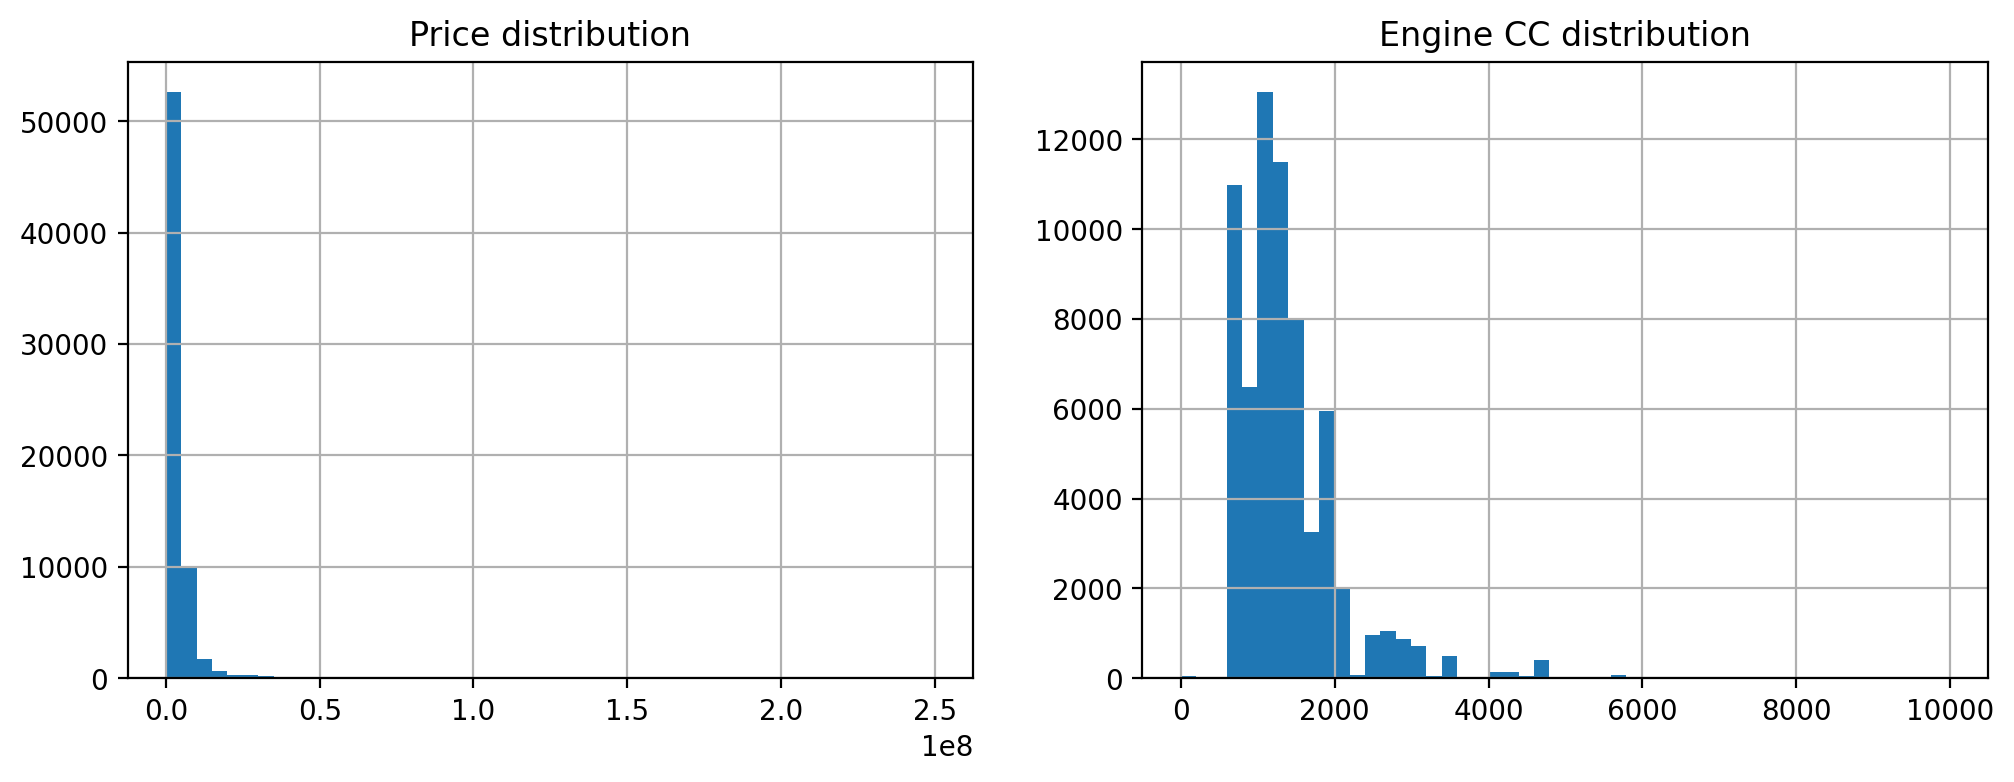

In [9]:
display(df.describe(include='all').T.head(20))
na = df.isna().mean().sort_values(ascending=False)
print('Missing ratio (top 20):')
print(na.head(20))

# Basic validations
assert df[target].notna().sum() > 100, 'Insufficient target values.'
assert df[target].max() < 1e9, 'Target out of expected range.'
if 'modelDate' in df:
    try:
        yr = pd.to_numeric(df['modelDate'], errors='coerce')
        assert (yr.dropna() >= 1960).all(), 'Year too small found.'
        assert (yr.dropna() <= 2030).all(), 'Year too large found.'
    except Exception:
        pass

# Quick plots
fig, ax = plt.subplots(1,2, figsize=(12,4))
_ = df[target].dropna().hist(ax=ax[0], bins=50)
ax[0].set_title('Price distribution')
if 'engineDisplacement' in df:
    df['engineDisplacement'].dropna().hist(ax=ax[1], bins=50)
    ax[1].set_title('Engine CC distribution')
plt.show()

## 5) Train/validation/test split

In [34]:
work = df.copy()
# Choose a minimal, robust feature set to start; expand later
candidate_cats = [c for c in ['brand','model','fuelType','vehicleTransmission','seller_location','bodyType'] if c in work]
candidate_nums = [c for c in ['engineDisplacement','mileageFromOdometer','modelDate'] if c in work]
feature_cols = candidate_cats + candidate_nums
print('Using features:', feature_cols)

work = work.dropna(subset=[target])
X = work[feature_cols]
y = work[target].astype(float)

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=SEED)
X_valid, X_test, y_valid, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=SEED)
list(map(len, [X_train, X_valid, X_test]))

Using features: ['brand', 'model', 'fuelType', 'vehicleTransmission', 'seller_location', 'bodyType', 'engineDisplacement', 'mileageFromOdometer', 'modelDate']


[46370, 9936, 9937]

## 6) Feature engineering and preprocessing pipeline

In [35]:
num_features = [c for c in X_train.columns if c in ['engineDisplacement','mileageFromOdometer','modelDate']]
cat_features = [c for c in X_train.columns if c not in num_features]

# Ensure pandas nullable dtypes are cast to object and NA -> np.nan for sklearn compatibility
X_train = X_train.copy()
X_valid = X_valid.copy()
for c in cat_features:
    if c in X_train.columns:
        X_train[c] = X_train[c].astype('object')
        X_train[c] = X_train[c].where(pd.notna(X_train[c]), np.nan)
    if c in X_valid.columns:
        X_valid[c] = X_valid[c].astype('object')
        X_valid[c] = X_valid[c].where(pd.notna(X_valid[c]), np.nan)

for c in num_features:
    if c in X_train.columns:
        X_train[c] = pd.to_numeric(X_train[c], errors='coerce')
    if c in X_valid.columns:
        X_valid[c] = pd.to_numeric(X_valid[c], errors='coerce')

num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median', missing_values=np.nan)),
    ('scaler', StandardScaler())
])

cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent', missing_values=np.nan)),
    ('ohe', OneHotEncoder(handle_unknown='ignore'))
])

pre = ColumnTransformer([
    ('num', num_pipe, num_features),
    ('cat', cat_pipe, cat_features)
])

# Baseline (for reference)
dummy = Pipeline([
    ('pre', pre),
    ('est', DummyRegressor(strategy='median'))
])

%time dummy.fit(X_train, y_train)
y_pred = dummy.predict(X_valid)
# Robust to sklearn versions with/without `squared` param
try:
    rmse = mean_squared_error(y_valid, y_pred, squared=False)
except TypeError:
    rmse = np.sqrt(mean_squared_error(y_valid, y_pred))
print('Dummy RMSE:', rmse)

CPU times: total: 297 ms
Wall time: 315 ms
Dummy RMSE: 6707661.958665267


## 7) Baseline and real models

## 8) Training with cross-validation

## 9) Evaluation and diagnostics

In [36]:
models = {
    'linreg': LinearRegression(),
    'rf': RandomForestRegressor(n_estimators=300, max_depth=None, n_jobs=-1, random_state=SEED),
}
try:
    from xgboost import XGBRegressor
    models['xgb'] = XGBRegressor(
        n_estimators=500, max_depth=8, learning_rate=0.05, subsample=0.8,
        colsample_bytree=0.8, reg_lambda=1.0, random_state=SEED, tree_method='hist'
    )
except Exception:
    pass

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
results = {}
for name, est in models.items():
    pipe = Pipeline([
        ('pre', pre),
        ('est', est)
    ])
    t0 = time.time()
    scores = cross_validate(pipe, X_train, y_train, scoring='neg_root_mean_squared_error', cv=cv, n_jobs=-1, return_train_score=True)
    dt_s = time.time() - t0
    rmse_val = -scores['test_score'].mean()
    rmse_tr = -scores['train_score'].mean()
    results[name] = {'rmse_val': rmse_val, 'rmse_tr': rmse_tr, 'time_s': dt_s}

pd.DataFrame(results).T.sort_values('rmse_val')

,rmse_val,rmse_tr,time_s
xgb,1.735128e+06,6.936970e+05,31.416826
rf,1.928913e+06,7.361426e+05,1711.742695
linreg,2.529396e+06,1.646118e+06,9.034342


Best model: xgb {'rmse_val': np.float64(1735128.325925061), 'rmse_tr': np.float64(693696.9932813914), 'time_s': 31.416825771331787}
CPU times: total: 29.9 s
Wall time: 4.77 s
CPU times: total: 29.9 s
Wall time: 4.77 s
{'RMSE': np.float64(1965742.0313587065), 'MAE': 495971.70735508704, 'R2': 0.9163985265901247}
{'RMSE': np.float64(1965742.0313587065), 'MAE': 495971.70735508704, 'R2': 0.9163985265901247}


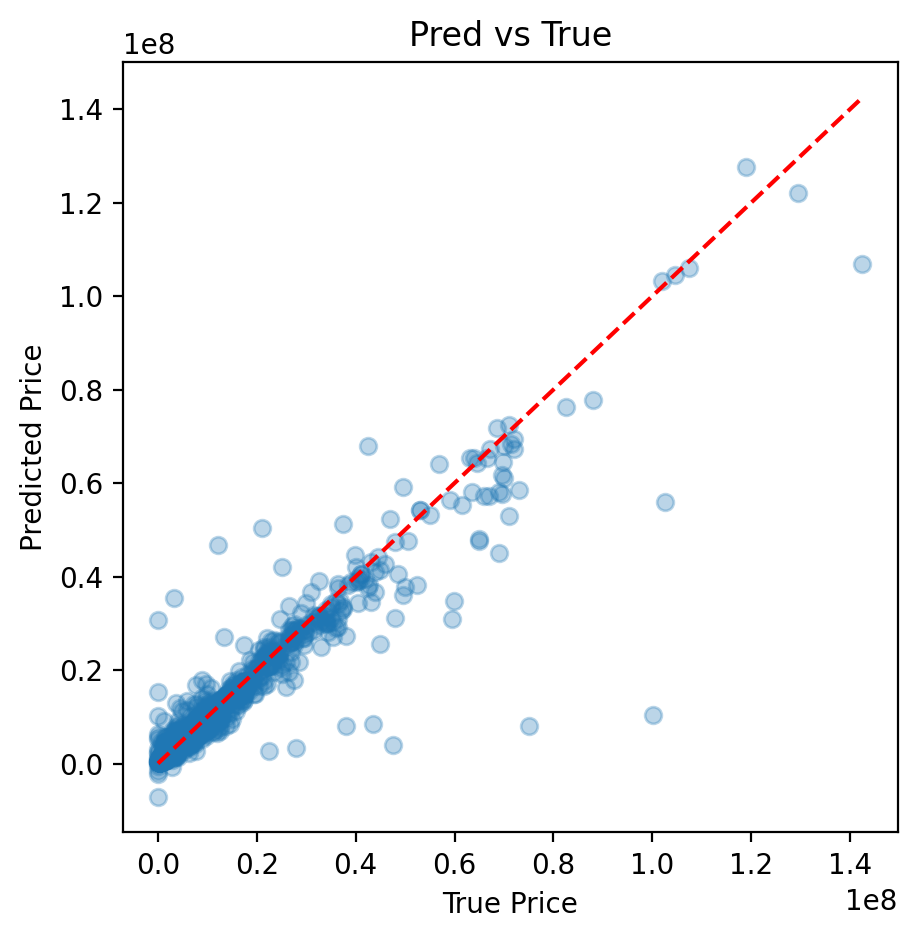

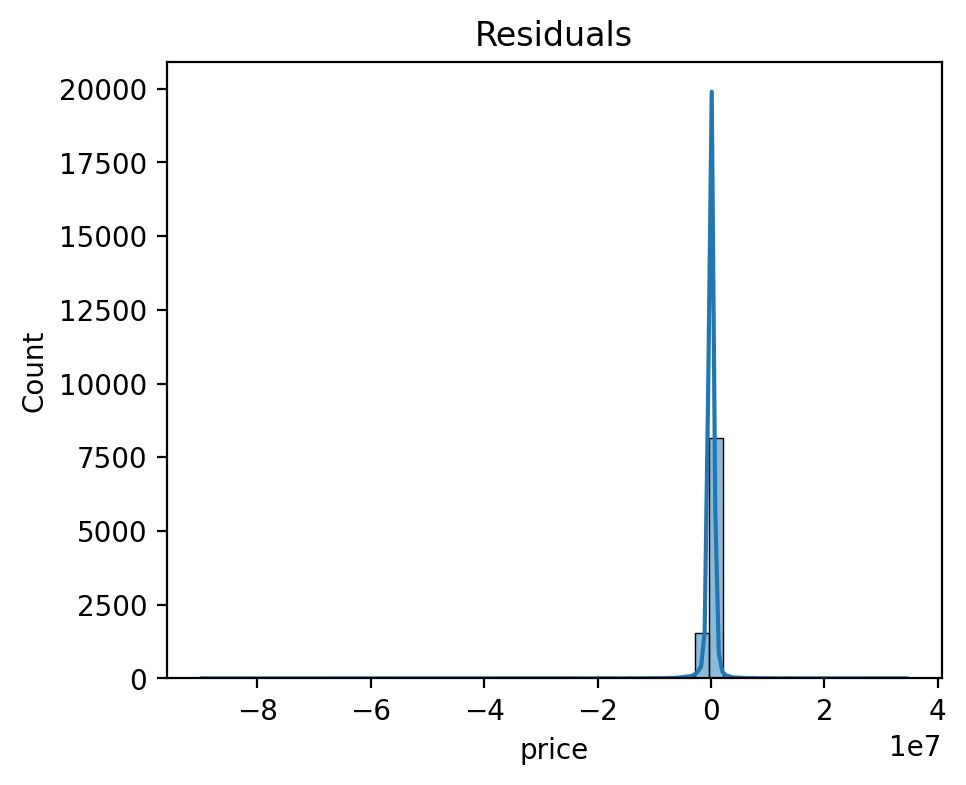

In [37]:
# Pick best by CV RMSE and fit on train+valid
best_name = min(results, key=lambda k: results[k]['rmse_val'])
print('Best model:', best_name, results[best_name])

best_est = {
    'linreg': LinearRegression(),
    'rf': RandomForestRegressor(n_estimators=300, max_depth=None, n_jobs=-1, random_state=SEED),
}
try:
    from xgboost import XGBRegressor
    best_est['xgb'] = XGBRegressor(
        n_estimators=500, max_depth=8, learning_rate=0.05, subsample=0.8,
        colsample_bytree=0.8, reg_lambda=1.0, random_state=SEED, tree_method='hist'
    )
except Exception:
    pass

pipe_best = Pipeline([
    ('pre', pre),
    ('est', best_est[best_name])
])

X_tr = pd.concat([X_train, X_valid], axis=0)
y_tr = pd.concat([y_train, y_valid], axis=0)
%time pipe_best.fit(X_tr, y_tr)

# Sanitize X_test dtypes/NA for sklearn transformers
Xt = X_test.copy()
for c in [col for col in Xt.columns if col in X_train.columns and col not in ['engineDisplacement','mileageFromOdometer','modelDate']]:
    try:
        Xt[c] = Xt[c].astype('object')
        Xt[c] = Xt[c].where(pd.notna(Xt[c]), np.nan)
    except Exception:
        pass
for c in [col for col in Xt.columns if col in ['engineDisplacement','mileageFromOdometer','modelDate']]:
    Xt[c] = pd.to_numeric(Xt[c], errors='coerce')

pred = pipe_best.predict(Xt)
# Robust to sklearn versions with/without `squared` param
try:
    rmse = mean_squared_error(y_test, pred, squared=False)
except TypeError:
    rmse = np.sqrt(mean_squared_error(y_test, pred))
mae = mean_absolute_error(y_test, pred)
r2 = r2_score(y_test, pred)
print({'RMSE': rmse, 'MAE': mae, 'R2': r2})

plt.figure(figsize=(5,5))
plt.scatter(y_test, pred, alpha=0.3)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('True Price')
plt.ylabel('Predicted Price')
plt.title('Pred vs True')
plt.show()

plt.figure(figsize=(5,4))
resid = pred - y_test
sns.histplot(resid, bins=50, kde=True)
plt.title('Residuals')
plt.show()

In [38]:
# Recompute metrics from fitted pipe_best using sanitized X_test (in case prior cell was interrupted)
Xt_metrics = X_test.copy()
for c in [col for col in Xt_metrics.columns if col in X_train.columns and col not in ['engineDisplacement','mileageFromOdometer','modelDate']]:
    Xt_metrics[c] = Xt_metrics[c].astype('object')
    Xt_metrics[c] = Xt_metrics[c].where(pd.notna(Xt_metrics[c]), np.nan)
for c in [col for col in Xt_metrics.columns if col in ['engineDisplacement','mileageFromOdometer','modelDate']]:
    Xt_metrics[c] = pd.to_numeric(Xt_metrics[c], errors='coerce')

pred = pipe_best.predict(Xt_metrics)
try:
    rmse = mean_squared_error(y_test, pred, squared=False)
except TypeError:
    rmse = np.sqrt(mean_squared_error(y_test, pred))
mae = mean_absolute_error(y_test, pred)
r2 = r2_score(y_test, pred)
print({'RMSE': rmse, 'MAE': mae, 'R2': r2})

{'RMSE': np.float64(1965742.0313587065), 'MAE': 495971.70735508704, 'R2': 0.9163985265901247}


## 10) Hyperparameter tuning (optional)

In [16]:
from scipy.stats import randint as sp_randint, uniform as sp_uniform
rf_pipe = Pipeline([
    ('pre', pre),
    ('est', RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1))
])
param_dist = {
    'est__max_depth': sp_randint(6, 20),
    'est__min_samples_split': sp_randint(2, 20),
    'est__min_samples_leaf': sp_randint(1, 10),
    'est__max_features': ['sqrt', 'log2', None]
}

rs = RandomizedSearchCV(rf_pipe, param_distributions=param_dist, n_iter=25, cv=3, scoring='neg_root_mean_squared_error', random_state=SEED, n_jobs=-1)
%time rs.fit(X_train, y_train)
print('Best RF params:', rs.best_params_)
print('Best RF RMSE:', -rs.best_score_)

d:\annacond\Lib\site-packages\sklearn\impute\_base.py:635: UserWarning: Skipping features without any observed values: ['bodyType']. At least one non-missing value is needed for imputation with strategy='most_frequent'.
  warnings.warn(


CPU times: total: 10min 13s
Wall time: 17min 17s
Best RF params: {'est__max_depth': 16, 'est__max_features': None, 'est__min_samples_leaf': 3, 'est__min_samples_split': 13}
Best RF RMSE: 2586316.129847853


## 11) Persist artifacts (model, preprocessor, metrics)

In [39]:
models_dir = root / 'models'
models_dir.mkdir(parents=True, exist_ok=True)
ts = dt.datetime.now().strftime('%Y%m%d_%H%M%S')
art_prefix = f'pakwheels_price_{best_name}_{ts}'

model_path = models_dir / f'{art_prefix}.joblib'
joblib.dump(pipe_best, model_path)
print('Saved model ->', model_path)

metrics = {'rmse': float(rmse), 'mae': float(mae), 'r2': float(r2), 'cv': results[best_name]}
metrics_path = models_dir / f'{art_prefix}_metrics.json'
with open(metrics_path, 'w', encoding='utf-8') as f:
    json.dump(metrics, f, indent=2)
print('Saved metrics ->', metrics_path)

Saved model -> d:\data_scrapping_pakwheels\models\pakwheels_price_xgb_20250812_223847.joblib
Saved metrics -> d:\data_scrapping_pakwheels\models\pakwheels_price_xgb_20250812_223847_metrics.json


## 12) Inference pipeline (batch and single)

In [40]:
from typing import List, Dict

def load_model(path: str):
    return joblib.load(path)

example = X_test.iloc[:3].copy()
# Sanitize example similarly to X_test
for c in [col for col in example.columns if col in X_train.columns and col not in ['engineDisplacement','mileageFromOdometer','modelDate']]:
    try:
        example[c] = example[c].astype('object')
        example[c] = example[c].where(pd.notna(example[c]), np.nan)
    except Exception:
        pass
for c in [col for col in example.columns if col in ['engineDisplacement','mileageFromOdometer','modelDate']]:
    example[c] = pd.to_numeric(example[c], errors='coerce')

print('Example rows for prediction:')
print(example)

preds = pipe_best.predict(example)
preds

Example rows for prediction:
          brand             model fuelType vehicleTransmission  \
47830    Toyota  Corolla XLi VVTi   Petrol              Manual   
22152    Suzuki          Alto VXR   Petrol              Manual   
711    Infiniti              FX35   Petrol              Manual   

      seller_location   bodyType  engineDisplacement  mileageFromOdometer  \
47830          Lahore      Sedan              1300.0              10000.0   
22152        Sargodha  Hatchback               660.0                 14.0   
711           Dhatmal        NaN               880.0              60000.0   

       modelDate  
47830     2009.0  
22152     2025.0  
711       1988.0  


array([2370841.2, 2934816. ,  458300.2], dtype=float32)

## 13) Unit tests (pytest via VS Code Test Explorer)

- Create tests under `tests/` (e.g., `tests/test_data.py`, `tests/test_model.py`).
- Check schema, non-null target, and minimum metric thresholds.
- Run tests from the Testing panel in VS Code.

## 14) CLI entrypoint for training (run from VS Code Terminal)

Use the snippet below to create a `train.py` CLI that reproduces this pipeline.

In [41]:
# Example CLI (copy to train.py and run: python train.py --input data/raw/<file>.csv)
import argparse

def main():
    ap = argparse.ArgumentParser()
    ap.add_argument('--input', required=True)
    ap.add_argument('--target', default='price')
    ap.add_argument('--seed', type=int, default=42)
    args = ap.parse_args()
    df = pd.read_csv(args.input, low_memory=False)
    # reuse feature set
    feature_cols = [c for c in ['brand','model','fuelType','vehicleTransmission','seller_location','bodyType','engineDisplacement','mileageFromOdometer','modelDate'] if c in df]
    work = df.dropna(subset=[args.target]).copy()
    X, y = work[feature_cols], work[args.target].astype(float)
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=args.seed)
    pre = ColumnTransformer([
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), [c for c in feature_cols if c in ['engineDisplacement','mileageFromOdometer','modelDate']]),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('ohe', OneHotEncoder(handle_unknown='ignore'))]), [c for c in feature_cols if c not in ['engineDisplacement','mileageFromOdometer','modelDate']])
    ])
    model = Pipeline([('pre', pre), ('est', RandomForestRegressor(n_estimators=400, n_jobs=-1, random_state=args.seed))])
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    print('RMSE:', mean_squared_error(y_te, pred, squared=False))

if __name__ == '__main__':
    pass  # This cell is illustrative; copy to a .py file to use as a CLI.

In [32]:
# Enrich missing fields from free-text (title/description) using simple regex/heuristics
import re
import math
import numpy as np
import pandas as pd
from typing import Dict, Optional

print("Enrichment: parsing listing text to backfill missing fields…")

# 1) Utilities
num_re = re.compile(r"(?<!\d)(\d{1,3}(?:[\,\.]\d{3})+|\d+(?:\.\d+)?)(?!\d)")
km_re = re.compile(r"(\d[\d,\.]*?)\s*(?:km|kms|kilometer|kilometers)\b", re.I)
cc_re = re.compile(r"(\d{3,4})\s*cc\b", re.I)
year_re = re.compile(r"\b(19\d{2}|20\d{2})\b")
price_pk_re = re.compile(r"\b(?:pkr|rs\.?|rupees)\s*([\d,\.]+)\b", re.I)
price_unit_re = re.compile(r"\b(?:pkr\s*)?([\d,\.]+)\s*(lacs?|lac|million|m|crore|cr)\b", re.I)
# Stop location at next delimiter like ' for', ',', '.' or end
city_in_re = re.compile(r"for sale in\s*([A-Za-z\-\s]+?)(?:\s+for\b|,|\.|$)", re.I)

colors = {
    'white','black','silver','grey','gray','blue','red','green','yellow','gold','brown','maroon','beige','purple','orange'
}
body_types = {'hatchback','sedan','suv','crossover','mpv','van','wagon','coupe','convertible','jeep','pickup'}
fuels = {'petrol','diesel','cng','hybrid','electric'}
transmissions = {'automatic','manual','cvt','ags','auto'}
conditions = {'used','new','reconditioned'}

known_makes = {
    'suzuki','toyota','honda','daihatsu','hyundai','kia','nissan','mitsubishi','mercedes','bmw','audi','changan','prince','faw','mg','proton','peugeot','dfsk',
}

# Model -> body type hints (best-effort)
model_body_map = {
    # Suzuki
    'wagon r': 'Hatchback', 'alto': 'Hatchback', 'cultus': 'Hatchback', 'swift': 'Hatchback', 'mehran': 'Hatchback', 'bolan': 'Van',
    # Toyota
    'corolla': 'Sedan', 'yaris': 'Sedan', 'vitz': 'Hatchback', 'aqua': 'Hatchback', 'prius': 'Hatchback', 'fortuner': 'SUV', 'hilux': 'Pickup', 'passo': 'Hatchback',
    # Honda
    'civic': 'Sedan', 'city': 'Sedan', 'fit': 'Hatchback', 'vezel': 'Crossover', 'br-v': 'MPV', 'brv': 'MPV',
    # Nissan / Daihatsu
    'dayz': 'Hatchback', 'mira': 'Hatchback', 'move': 'Hatchback',
    # Hyundai / KIA
    'tucson': 'SUV', 'elantra': 'Sedan', 'sonata': 'Sedan', 'sportage': 'SUV', 'picanto': 'Hatchback',
    # Others common
    'mg hs': 'SUV', 'mg zs': 'SUV', 'alsvin': 'Sedan', 'saga': 'Sedan', 'pearl': 'Hatchback'
}

# Normalize helpers

def parse_price_to_pkr(text: str) -> Optional[int]:
    if not text:
        return None
    t = text.lower()
    # Prefer unit-based parsing like 29.9 lacs, 2.5 million, 0.3 crore
    m = price_unit_re.search(t)
    if m:
        num = float(m.group(1).replace(',', ''))
        unit = m.group(2).lower()
        if unit.startswith('lac'):
            return int(num * 100_000)
        if unit.startswith('m') or unit.startswith('million'):
            return int(num * 1_000_000)
        if unit.startswith('cr') or unit.startswith('crore'):
            return int(num * 10_000_000)
    # Direct PKR number like PKR 2,990,000
    m = price_pk_re.search(t)
    if m:
        val = m.group(1).replace(',', '')
        try:
            return int(float(val))
        except Exception:
            pass
    return None


def extract_simple_token(text: str, candidates: set) -> Optional[str]:
    if not text:
        return None
    t = text.lower()
    for w in candidates:
        if re.search(rf"\b{re.escape(w)}\b", t):
            return next(iter({w}))
    return None


def parse_make_model_variant(title: str, year: Optional[int]) -> Dict[str, Optional[str]]:
    # Very light heuristic: if title starts with a known make, take subsequent capitalized tokens as model until year/cc/etc.
    res = {"make": None, "model": None, "variant": None}
    if not title:
        return res
    tokens = title.split()
    if not tokens:
        return res
    # find make
    mk = None
    start = 0
    for i, tok in enumerate(tokens):
        low = tok.lower().strip(',:-()')
        if low in known_makes:
            mk = tokens[i]
            start = i + 1
            break
    if mk is None:
        # try first token as make if capitalized
        first = tokens[0]
        if first and first[0].isupper():
            mk = first
            start = 1
        else:
            return res
    res["make"] = mk.title()
    # find stop index at year or keyword
    stop = len(tokens)
    for j in range(start, len(tokens)):
        tok = tokens[j]
        if year and re.fullmatch(r"\d{4}", tok):
            stop = j
            break
        low = tok.lower().strip(',./')
        if low in {'used','new','for','sale','in','pkr'}:
            stop = j
            break
    mid = tokens[start:stop]
    if not mid:
        return res
    # Heuristic: last of mid is variant, others model (e.g., Wagon R AGS -> model: Wagon R, variant: AGS)
    if len(mid) >= 2:
        res["variant"] = mid[-1].upper() if mid[-1].isalpha() else mid[-1]
        res["model"] = " ".join(mid[:-1]).title()
    else:
        res["model"] = mid[0].title()
    return res


def infer_body_type(make: Optional[str], model: Optional[str], text: str) -> Optional[str]:
    # Avoid treating 'Wagon R' as body type 'Wagon'
    t = text.lower()
    if 'wagon r' in t:
        avoid_wagon = True
    else:
        avoid_wagon = False
    # Prefer explicit label tokens if present and not part of known model phrase
    bt = extract_simple_token(text, body_types)
    if bt:
        if bt == 'wagon' and avoid_wagon:
            bt = None
        if bt:
            return bt.title()
    # Fallback to model-based lookup
    key = (model or '').lower().strip()
    key = re.sub(r"\s+", ' ', key)
    if key in model_body_map:
        return model_body_map[key]
    # Try partial contains
    for k, v in model_body_map.items():
        if k in key:
            return v
    return None


def infer_fuel_type(text: str, make: Optional[str], model: Optional[str]) -> Optional[str]:
    t = text.lower()
    if re.search(r"\bhybrid\b", t):
        return 'Hybrid'
    if re.search(r"\belectric|ev\b", t):
        return 'Electric'
    if re.search(r"\bdiesel\b", t):
        return 'Diesel'
    if re.search(r"\bcng\b", t):
        return 'CNG'
    # Default: Petrol if nothing else found
    return 'Petrol'


def parse_text_record(text: str) -> Dict[str, Optional[object]]:
    out: Dict[str, Optional[object]] = {
        'make': None, 'model': None, 'variant': None, 'year': None,
        'condition': None, 'location': None, 'price_pkr': None,
        'engine_cc': None, 'color': None, 'mileage_km': None,
        'transmission': None, 'fuel_type': None, 'body_type': None,
    }
    if not text:
        return out
    t = str(text)
    # Year
    my = None
    m = year_re.search(t)
    if m:
        try:
            yv = int(m.group(1))
            if 1980 <= yv <= 2030:
                my = yv
        except Exception:
            pass
    out['year'] = my
    # Price
    out['price_pkr'] = parse_price_to_pkr(t)
    # Engine CC
    m = cc_re.search(t)
    if m:
        try:
            out['engine_cc'] = int(m.group(1))
        except Exception:
            pass
    # Mileage
    m = km_re.search(t)
    if m:
        val = m.group(1).replace(',', '')
        try:
            out['mileage_km'] = int(float(val))
        except Exception:
            pass
    # Simple categorical tokens
    col = extract_simple_token(t, colors)
    if col:
        out['color'] = 'Gray' if col == 'grey' else col.title()
    fu = extract_simple_token(t, fuels)
    if fu:
        out['fuel_type'] = fu.title()
    tr = extract_simple_token(t, transmissions)
    if tr:
        out['transmission'] = 'Automatic' if tr in {'automatic','auto','cvt','ags'} else tr.title()
    cd = extract_simple_token(t, conditions)
    if cd:
        out['condition'] = cd.title()
    # Location
    m = city_in_re.search(t)
    if m:
        out['location'] = m.group(1).strip().title()
    # Make/Model/Variant from title-ish prefix
    mmv = parse_make_model_variant(t.split('.')[:1][0], out['year'])
    out.update(mmv)
    # Infer body type if missing
    if not out['body_type']:
        out['body_type'] = infer_body_type(out.get('make'), out.get('model'), t)
    # Infer fuel type if missing -> default Petrol if no other evidence
    if not out['fuel_type']:
        out['fuel_type'] = infer_fuel_type(t, out.get('make'), out.get('model'))
    return out

# 2) Build a combined text per row (title + description + any details columns)
text_cols = [c for c in df.columns if any(k in c.lower() for k in ['title','desc','detail','headline','summary'])]
if not text_cols:
    print("No obvious text columns found; using 'name' if exists.")
    if 'name' in df.columns:
        text_cols = ['name']

def combine_text(row) -> str:
    parts = []
    for c in text_cols:
        val = row.get(c)
        if pd.notna(val) and str(val).strip():
            parts.append(str(val))
    return ' '.join(parts)

combined_text = df[text_cols].apply(lambda r: combine_text(r), axis=1) if text_cols else pd.Series([None]*len(df), index=df.index)

# 3) Parse all rows
parsed = combined_text.apply(parse_text_record)
parsed_df = pd.DataFrame(list(parsed.values), index=df.index)

# 4) Backfill df where missing/empty; ensure new columns are object dtype when created
fields = ['make','model','variant','year','condition','location','price_pkr','engine_cc','color','mileage_km','transmission','fuel_type','body_type']
filled_counts = {}
for f in fields:
    if f not in df.columns:
        df[f] = pd.Series([np.nan]*len(df), dtype='object')
    # Build mask of missing/empty
    miss = df[f].isna() | (df[f].astype(str).str.strip().eq(''))
    before = int(miss.sum())
    if f in parsed_df.columns:
        df.loc[miss, f] = parsed_df.loc[miss, f]
    after = int((df[f].isna() | (df[f].astype(str).str.strip().eq(''))).sum())
    filled_counts[f] = before - after

# 5) Light type casts
for f in ['year','engine_cc','mileage_km','price_pkr']:
    if f in df.columns:
        df[f] = pd.to_numeric(df[f], errors='coerce')

# 6) Report
print("Text enrichment complete.")
print({k: v for k, v in filled_counts.items() if v > 0})

# 7) Quick demo using the provided example text
example = "Suzuki Wagon R AGS 2022 Used for sale in Islamabad for PKR 29.9 lacs . Buy this 1000 cc, Grey 60000 KM Driven, Automatic Car"
print("Example parse:", parse_text_record(example))

Enrichment: parsing listing text to backfill missing fields…
Text enrichment complete.
{'fuel_type': 64041, 'body_type': 44486}
Example parse: {'make': 'Suzuki', 'model': 'Wagon R', 'variant': 'AGS', 'year': 2022, 'condition': 'Used', 'location': 'Islamabad', 'price_pkr': 2990000, 'engine_cc': 1000, 'color': 'Gray', 'mileage_km': 60000, 'transmission': 'Automatic', 'fuel_type': 'Petrol', 'body_type': 'Hatchback'}
Text enrichment complete.
{'fuel_type': 64041, 'body_type': 44486}
Example parse: {'make': 'Suzuki', 'model': 'Wagon R', 'variant': 'AGS', 'year': 2022, 'condition': 'Used', 'location': 'Islamabad', 'price_pkr': 2990000, 'engine_cc': 1000, 'color': 'Gray', 'mileage_km': 60000, 'transmission': 'Automatic', 'fuel_type': 'Petrol', 'body_type': 'Hatchback'}


In [33]:
# Map enriched columns into canonical feature columns and coerce dtypes safely
import numpy as np
import pandas as pd

cat_targets = ['brand','model','fuelType','vehicleTransmission','seller_location','bodyType']
for c in cat_targets:
    if c in df.columns:
        try:
            df[c] = df[c].astype('object')
        except Exception:
            pass

# Prefer enriched text if base columns are missing/empty
if 'brand' in df.columns and 'make' in df.columns:
    mask = df['brand'].isna() | df['brand'].astype(str).str.strip().eq('')
    df.loc[mask, 'brand'] = df.loc[mask, 'make'].astype('object')

# model: enrichment already populated df['model'] when empty; ensure object dtype
if 'model' in df.columns:
    df['model'] = df['model'].astype('object')

# Normalize transmission from enrichment
if 'vehicleTransmission' in df.columns:
    if 'transmission' in df.columns:
        mask = df['vehicleTransmission'].isna() | df['vehicleTransmission'].astype(str).str.strip().eq('')
        df.loc[mask, 'vehicleTransmission'] = df.loc[mask, 'transmission'].astype('object')
    # Canonicalize caps
    df['vehicleTransmission'] = df['vehicleTransmission'].astype('object').str.strip().str.title()
    df['vehicleTransmission'] = df['vehicleTransmission'].replace({'Ags': 'Automatic', 'Cvt': 'Automatic', 'Auto': 'Automatic'})

# Normalize fuel type with defaults from enrichment
if 'fuelType' in df.columns:
    if 'fuel_type' in df.columns:
        mask = df['fuelType'].isna() | df['fuelType'].astype(str).str.strip().eq('')
        df.loc[mask, 'fuelType'] = df.loc[mask, 'fuel_type'].astype('object')
    df['fuelType'] = df['fuelType'].astype('object').str.strip().str.title()
    df['fuelType'] = df['fuelType'].replace({'Ev': 'Electric'})

# Normalize body type with enrichment and title-case
if 'bodyType' in df.columns:
    if 'body_type' in df.columns:
        mask = df['bodyType'].isna() | df['bodyType'].astype(str).str.strip().eq('')
        df.loc[mask, 'bodyType'] = df.loc[mask, 'body_type'].astype('object')
    df['bodyType'] = df['bodyType'].astype('object').str.strip().str.title()

# seller_location from enrichment 'location'
if 'seller_location' in df.columns and 'location' in df.columns:
    mask = df['seller_location'].isna() | df['seller_location'].astype(str).str.strip().eq('')
    df.loc[mask, 'seller_location'] = df.loc[mask, 'location'].astype('object')

# Numeric coerces
for c_from, c_to in [('engine_cc','engineDisplacement'), ('mileage_km','mileageFromOdometer'), ('year','modelDate'), ('price_pkr','price')]:
    if c_to in df.columns and c_from in df.columns:
        mask = df[c_to].isna()
        df.loc[mask, c_to] = pd.to_numeric(df.loc[mask, c_from], errors='coerce')

print('Canonical fields backfilled from enrichment where empty, and categorical dtypes set to object.')

Canonical fields backfilled from enrichment where empty, and categorical dtypes set to object.


In [44]:
# Save enriched dataset to data/processed for reuse
from pathlib import Path
import datetime as dt

processed = root / 'data' / 'processed'
processed.mkdir(parents=True, exist_ok=True)

stamp = dt.datetime.now().strftime('%Y%m%d_%H%M%S')
out_csv = processed / f'enriched_{stamp}.csv'
latest_csv = processed / 'enriched_latest.csv'

# Ensure df exists and is DataFrame
assert 'df' in globals(), 'DataFrame df not found.'
assert hasattr(df, 'to_csv'), 'df is not a pandas DataFrame.'

df.to_csv(out_csv, index=False)
# Also refresh a stable name for convenient reloading
try:
    df.to_csv(latest_csv, index=False)
except Exception:
    pass

print('Saved enriched CSV ->', out_csv)
print('Updated enriched_latest.csv ->', latest_csv)
if 'fuelType' in df.columns:
    print('fuelType non-null:', int(df['fuelType'].notna().sum()))
if 'bodyType' in df.columns:
    print('bodyType non-null:', int(df['bodyType'].notna().sum()))

Saved enriched CSV -> d:\data_scrapping_pakwheels\data\processed\enriched_20250812_224227.csv
Updated enriched_latest.csv -> d:\data_scrapping_pakwheels\data\processed\enriched_latest.csv
fuelType non-null: 67020
bodyType non-null: 48160
